┏━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Code ┃ Binary ┃ Vout (V) ┃ Step (mV) ┃ ADC code ┃ ADC step ┃ ADC thrsh ┃
┡━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━┩
│  0   │ 0000   │    0.000 │         0 │        0 │        0 │       306 │
│  1   │ 0001   │    0.359 │       359 │      612 │      612 │       880 │
│  2   │ 0010   │    0.673 │       315 │     1149 │      537 │      1347 │
│  3   │ 0011   │    0.906 │       232 │     1546 │      397 │      1711 │
│  4   │ 0100   │    1.100 │       194 │     1877 │      331 │      2018 │
│  5   │ 0101   │    1.265 │       165 │     2159 │      282 │      2292 │
│  6   │ 0110   │    1.421 │       156 │     2425 │      266 │      2529 │
│  7   │ 0111   │    1.543 │       122 │     2633 │      208 │      2724 │
│  8   │ 1000   │    1.650 │       107 │     2816 │      183 │      2896 │
│  9   │ 1001   │    1.745 │        95 │     2977 │      161 │      3056 │
│ 10   │ 1010   │    1.838 │        93 │     3136 │      159 │      3200 │
│ 11   │ 1011   │    1.913 │        75 │     3264 │      128 │      3321 │
│ 12   │ 1100   │    1.980 │        67 │     3379 │      115 │      3431 │
│ 13   │ 1101   │    2.041 │        61 │     3484 │      105 │      3536 │
│ 14   │ 1110   │    2.103 │        61 │     3588 │      104 │      3631 │
│ 15   │ 1111   │    2.154 │        51 │     3675 │       87 │      4096 │
└──────┴────────┴──────────┴───────────┴──────────┴──────────┴───────────┘

const uint16_t config_adc_thrsh_lut[16] = {306, 880, 1347, 1711, 2018, 2292, 2529, 2724, 2896, 3056, 3200, 3321, 3431, 3536, 3631, 4096};
Copied to clipboard.


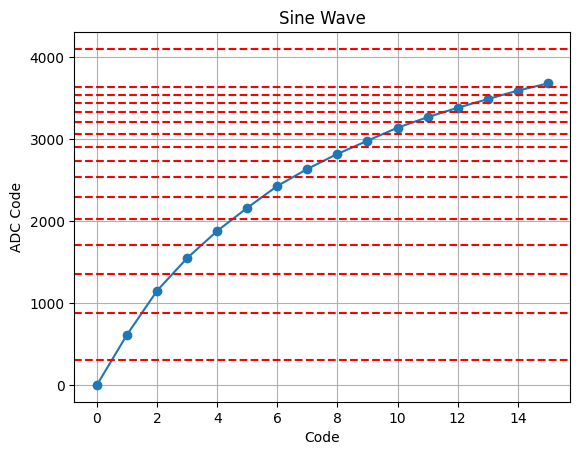

In [39]:
from rich.console import Console
from rich.table import Table
import pyperclip
import matplotlib.pyplot as plt
import numpy as np

# Calculate the voltage and adc reading for every r-2r code.
vref_V = 3.3
num_bits = 4
adc_resolution = 12
adc_reference_V = 2.4

# MUST be of length @ref num_bits!
resistors = [10_000, 20_000, 39_000, 82_000]
lower_r = 10_000


def calculate_parallel_r(r: list[int]) -> int | None:
    if len(r) == 0:
        return None

    reziprokal_r = 0
    for val in r:
        reziprokal_r += 1 / val
    return int(1 / reziprokal_r)


def calculate_vout(code: int, vref: float, num_bits: int,
                   lower_r: int) -> float:
    r_list = []
    for bit in range(num_bits):
        if (code >> (num_bits - 1 - bit) & 0x1):
            r_list.append(resistors[bit])
    upper_r = calculate_parallel_r(r_list)
    if not upper_r:
        return 0
    return vref * (lower_r / (lower_r + upper_r))


def get_adc_code_from_voltage(adc_resolution: int, adc_reference_V: float,
                              voltage: float) -> int:
    return int(pow(2, adc_resolution) * voltage / adc_reference_V)


console = Console()

table = Table(show_header=True, header_style="bold green")
table.add_column("Code", justify="left")
table.add_column("Binary", justify="left")
table.add_column("Vout (V)", justify="right")
table.add_column("Step (mV)", justify="right")
table.add_column("ADC code", justify="right")
table.add_column("ADC step", justify="right")
table.add_column("ADC thrsh", justify="right")

adc_code_prev = 0
vout_prev = 0.0
adc_step_list = []
adc_thrsh_list = []
adc_code_list = range(16)

for code in adc_code_list:
    vout = calculate_vout(code, vref_V, num_bits, lower_r)
    next_vout = calculate_vout(code + 1, vref_V, num_bits, lower_r)
    adc_code = get_adc_code_from_voltage(adc_resolution, adc_reference_V, vout)
    next_adc_code = get_adc_code_from_voltage(adc_resolution, adc_reference_V,
                                              next_vout)
    adc_thrsh = adc_code + int((next_adc_code - adc_code) / 2)
    if code == 15:
        adc_thrsh = pow(2, adc_resolution)
    adc_step_list.append(adc_code)
    adc_thrsh_list.append(adc_thrsh)
    table.add_row(f"{code:2d}", f"{code:04b}", f"{vout:.3f}",
                  f"{1000.0*(vout-vout_prev):.0f}", f"{adc_code:4d}",
                  f"{(adc_code-adc_code_prev):4d}", f"{adc_thrsh:4d}")
    adc_code_prev = adc_code
    vout_prev = vout
console.print(table)
adc_step_str = f"const uint16_t config_adc_thrsh_lut[16] = {{{', '.join([str(v) for v in adc_thrsh_list])}}};"
print(adc_step_str)
pyperclip.copy(adc_step_str)
print("Copied to clipboard.")

fig, ax = plt.subplots()
ax.plot(adc_code_list, adc_step_list, marker='o', linestyle='-')

for thrsh in adc_thrsh_list:
    plt.axhline(thrsh, color='r', linestyle='--')

ax.set(xlabel='Code', ylabel='ADC Code', title='Sine Wave')
ax.grid(True)

# plt.savefig("sine_wave.png")
plt.show()

In [21]:
# Regular R-2R calculation.

from rich.console import Console
from rich.table import Table

# Calculate the voltage and adc reading for every r-2r code.
vref_V = 3.3
num_bits = 4
adc_resolution = 12
adc_reference_V = 3.6


def calculate_vout(code: int, vref: float, num_bits: int) -> float:
    weighted_sum: int = 0
    for bit in range(num_bits):
        weighted_sum += (code >> bit & 0x1) / pow(2, num_bits - bit)
    return vref * weighted_sum


def get_adc_code_from_voltage(adc_resolution: int, adc_reference_V: float,
                              voltage: float) -> int:
    return int(pow(2, adc_resolution) * voltage / adc_reference_V)


console = Console()

table = Table(show_header=True, header_style="bold green")
table.add_column("Code", justify="left")
table.add_column("Binary", justify="left")
table.add_column("Vout (V)", justify="right")
table.add_column("ADC code", justify="right")

for code in range(16):
    vout = calculate_vout(code, vref_V, num_bits)
    adc_code = get_adc_code_from_voltage(adc_resolution, adc_reference_V, vout)
    table.add_row(f"{code:2d}", f"{code:04b}", f"{vout:.3f}", f"{adc_code:4d}")
console.print(table)

┏━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ Code ┃ Binary ┃ Vout (V) ┃ ADC code ┃
┡━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│  0   │ 0000   │    0.000 │        0 │
│  1   │ 0001   │    0.206 │      234 │
│  2   │ 0010   │    0.412 │      469 │
│  3   │ 0011   │    0.619 │      703 │
│  4   │ 0100   │    0.825 │      938 │
│  5   │ 0101   │    1.031 │     1173 │
│  6   │ 0110   │    1.237 │     1407 │
│  7   │ 0111   │    1.444 │     1642 │
│  8   │ 1000   │    1.650 │     1877 │
│  9   │ 1001   │    1.856 │     2112 │
│ 10   │ 1010   │    2.062 │     2346 │
│ 11   │ 1011   │    2.269 │     2581 │
│ 12   │ 1100   │    2.475 │     2815 │
│ 13   │ 1101   │    2.681 │     3050 │
│ 14   │ 1110   │    2.887 │     3285 │
│ 15   │ 1111   │    3.094 │     3520 │
└──────┴────────┴──────────┴──────────┘